# 🛫 PRC Data Challenge 2026 — Journal de recherche
**Équipe : `reliable-hamburger` · Objectif : #1 au leaderboard (RMSE, taxi-out time)**

Ce notebook est le **fil conducteur** du projet : chaque section documente une étape
de l'étude, les découvertes vérifiées, et le tableau des expériences. Il est généré
par `scripts/build_journal.py` et ré-exécutable de bout en bout.

## Le challenge en bref (faits vérifiés le 2026-09-01)
- **Cible** : `TAXITIME_SEC_mvt` des départs = `MVT_TIME_UTC − BLOCK_TIME_UTC` (vérifié : écart max 0.0 s).
- **Train** : année 2025 complète, 4 167 797 mouvements (DEP+ARR), 10 aéroports effectifs
  (LTAI/Antalya listé sur le site mais **absent des données**).
- **Test (leaderboard)** : `ranking.parquet` — janvier 2026 (10 aéroports) + juillet 2026
  (**EDDF, EGLL, EHAM uniquement**). 215 876 départs à prédire. Métrique : **RMSE**.
- **Info clé** : dans le ranking, seuls `BLOCK_TIME_UTC` et `TAXITIME_SEC` sont masqués.
  **L'heure de décollage réelle est fournie**, ainsi que tout le trafic environnant →
  problème de *reconstruction d'état*, pas de forecasting.
- Données externes **ouvertes autorisées** (le test étant dans le passé, la météo réelle
  de jan/juil 2026 est une donnée historique légale).
- Code final open-source (GPLv3) requis pour les prix. Deadline : **11 octobre 2026**.


In [1]:
# §0 — Setup
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from dc26 import load_movements_2025, load_ranking_2026, mirror_split, rmse, log_experiment, load_log
from dc26.validation import rmse_report

warnings.filterwarnings('ignore')

# Palette validée (dataviz skill, surface claire)
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
BLUE, SURFACE = PAL[0], "#fcfcfb"
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
    'axes.edgecolor': '#d8d7d2', 'axes.grid': True, 'grid.color': '#eceae5',
    'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
    'text.color': '#0b0b0b', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'font.size': 10, 'figure.dpi': 110,
})

mv = load_movements_2025()
rk = load_ranking_2026()
dep = mv[mv['PHASE_mvt'] == 'DEP'].copy()
print(f"2025: {len(mv):,} mouvements dont {len(dep):,} départs | ranking 2026: {len(rk):,} lignes")

2025: 4,167,797 mouvements dont 2,085,047 départs | ranking 2026: 431,843 lignes


## §1 — Audit des données
Volumes par aéroport et par mois, qualité de la cible. Points d'attention identifiés :
- 369 taxi-out **négatifs** (min −12 s), 584 cas **> 2 h** (max 131 167 s ≈ 36 h), 19 zéros ;
- LIRF (Rome) a un régime d'outliers extrême (σ ≈ 1 330 s vs ~350 ailleurs) — il pèsera
  lourd dans le RMSE de janvier ;
- aucun doublon de `MVT_ID`.

,n,moyenne,mediane,sigma,q99
AIRPORT,,,,,
LTFM,272965,1053,963,428,2587
EHAM,247951,785,742,318,1774
LFPG,239552,1020,954,453,2409
EGLL,239546,1364,1319,422,2701
EDDF,230141,863,837,330,1819
LEMD,212242,1015,985,313,1932
LEBL,179705,957,906,331,1962
EDDM,167334,812,774,302,1921
LIRF,160704,1195,1025,1332,4019


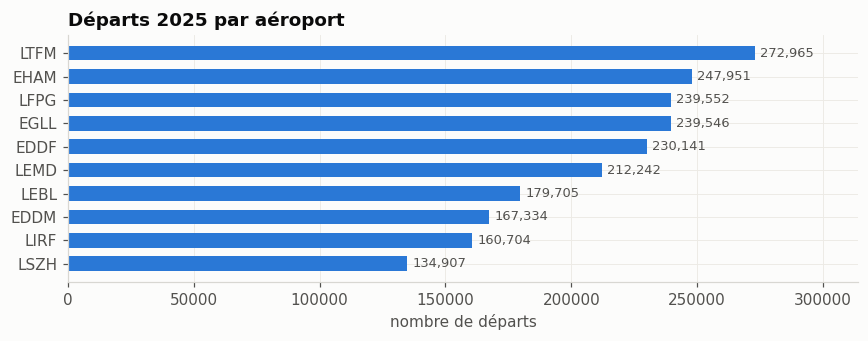

In [2]:
# §1 — volumes par aéroport (départs 2025) et stats cible
audit = dep.groupby('AIRPORT')['TAXITIME_SEC_mvt'].agg(
    n='count', moyenne='mean', mediane='median', sigma='std',
    q99=lambda x: x.quantile(0.99)).round(0).astype(int).sort_values('n', ascending=False)
display(audit)

fig, ax = plt.subplots(figsize=(8, 3.2))
a = audit.sort_values('n')
ax.barh(a.index, a['n'], color=BLUE, height=0.62)
ax.set_title('Départs 2025 par aéroport', loc='left', fontweight='bold')
ax.set_xlabel('nombre de départs')
for i, v in enumerate(a['n']):
    ax.text(v + 2000, i, f'{v:,}', va='center', fontsize=8.5, color='#52514e')
ax.set_xlim(0, a['n'].max() * 1.15)
plt.tight_layout(); plt.show()

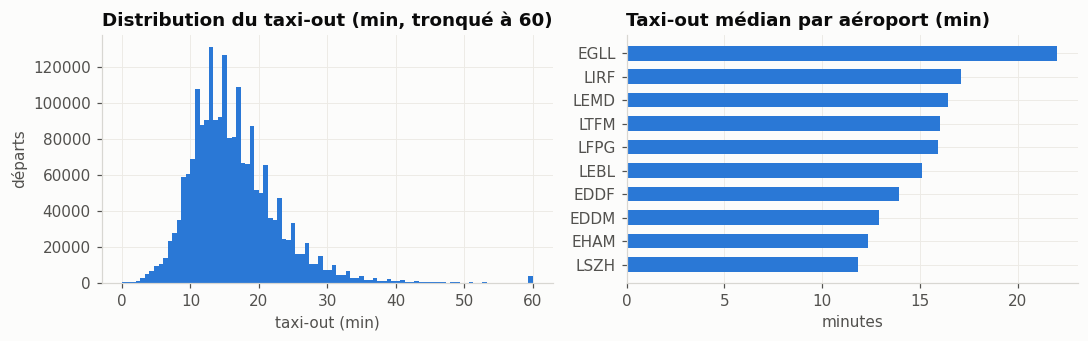

skewness=48.4 | negatifs=369 | >2h=584


In [3]:
# §1b — distribution de la cible (tronquée à 60 min pour la lisibilité)
t = dep['TAXITIME_SEC_mvt']
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(t.clip(0, 3600) / 60, bins=90, color=BLUE)
axes[0].set_title('Distribution du taxi-out (min, tronqué à 60)', loc='left', fontweight='bold')
axes[0].set_xlabel('taxi-out (min)'); axes[0].set_ylabel('départs')

am = dep.groupby('AIRPORT')['TAXITIME_SEC_mvt'].median().sort_values() / 60
axes[1].barh(am.index, am.values, color=BLUE, height=0.62)
axes[1].set_title('Taxi-out médian par aéroport (min)', loc='left', fontweight='bold')
axes[1].set_xlabel('minutes')
plt.tight_layout(); plt.show()
print(f"skewness={t.skew():.1f} | negatifs={(t<0).sum()} | >2h={(t>7200).sum()}")

## §2 — 🔑 Découverte n°1 : `AOBT_3_flt`
`AOBT_3` (Actual Off-Block Time, modèle M3 du Network Manager) est présent pour
**98,5 % des départs du fichier de ranking** — alors que `BLOCK_TIME_UTC` y est masqué.
Sur le train, l'écart `BLOCK_TIME − AOBT_3` a une **médiane de ~5 s** mais des queues
lourdes : quand le NM met à jour tardivement, AOBT_3 peut dévier de ±25 min.

→ `MVT_TIME − AOBT_3` est un prédicteur quasi direct de la cible pour la majorité des
vols ; le travail du modèle est d'apprendre **quand s'en méfier** et de corriger avec
les features d'état de l'aéroport.

couverture train: 98.9% | mediane=51s  IQR=[-122, 183]  q01=-1194  q99=803


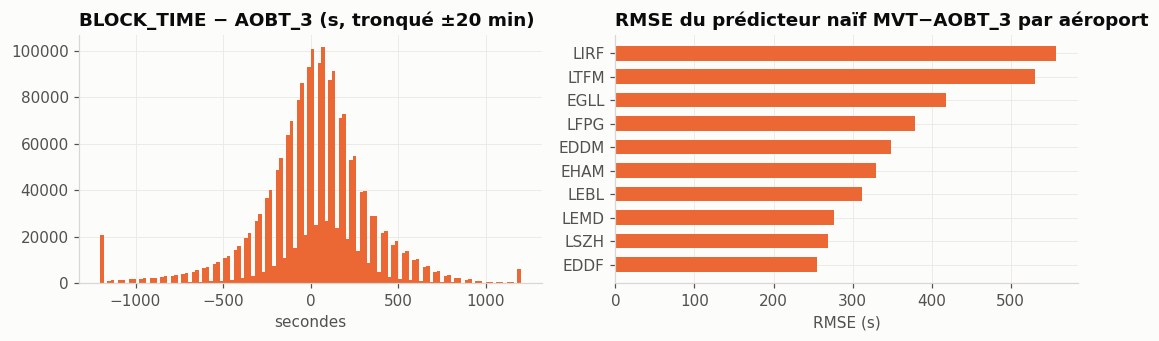

In [4]:
# §2 — qualité d'AOBT_3 et prédicteur naïf
m = dep['AOBT_3_flt'].notna()
gap = (dep.loc[m, 'BLOCK_TIME_UTC_mvt'] - dep.loc[m, 'AOBT_3_flt']).dt.total_seconds()
print(f"couverture train: {m.mean():.1%} | mediane={gap.median():.0f}s  IQR=[{gap.quantile(.25):.0f}, {gap.quantile(.75):.0f}]  q01={gap.quantile(.01):.0f}  q99={gap.quantile(.99):.0f}")

naive = (dep.loc[m, 'MVT_TIME_UTC_mvt'] - dep.loc[m, 'AOBT_3_flt']).dt.total_seconds()
err = naive - dep.loc[m, 'TAXITIME_SEC_mvt']
by_ap = dep.loc[m].assign(err=err).groupby('AIRPORT')['err'].apply(lambda e: float(np.sqrt((e**2).mean()))).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(gap.clip(-1200, 1200), bins=120, color=PAL[1])
axes[0].set_title('BLOCK_TIME − AOBT_3 (s, tronqué ±20 min)', loc='left', fontweight='bold')
axes[0].set_xlabel('secondes')
axes[1].barh(by_ap.index, by_ap.values, color=PAL[1], height=0.62)
axes[1].set_title('RMSE du prédicteur naïf MVT−AOBT_3 par aéroport', loc='left', fontweight='bold')
axes[1].set_xlabel('RMSE (s)')
plt.tight_layout(); plt.show()

## §3 — Structure du test et validation miroir
Composition vérifiée du leaderboard :

| Période | Aéroports | Départs | Poids RMSE² |
|---|---|---:|---:|
| Janvier 2026 | les 10 | 152 719 | ≈ 71 % |
| Juillet 2026 | EDDF, EGLL, EHAM | 63 157 | ≈ 29 % |

**Validation miroir** : holdout = janvier 2025 (10 aéroports) + juillet 2025 (3 hubs) ;
train = les 10 autres mois. Cette validation reproduit le mélange saisonnier et la
pondération du leaderboard — c'est notre juge de paix pour toutes les expériences.

In [5]:
# §3 — split miroir
train, val, val_part = mirror_split(dep)
print(f"train: {len(train):,} | holdout: {len(val):,}  (jan: {(val_part=='jan').sum():,}, jul-3hubs: {(val_part=='jul').sum():,})")
print(f"ratio jan/total holdout: {(val_part=='jan').mean():.1%}  (leaderboard reel: 70.7%)")

train: 1,866,728 | holdout: 218,319  (jan: 153,706, jul-3hubs: 64,613)
ratio jan/total holdout: 70.4%  (leaderboard reel: 70.7%)


## §4 — Baselines
Chaque niveau mesure le « prix » d'une source d'information. Toutes évaluées sur le
holdout miroir (RMSE en secondes).

In [6]:
# §4 — baselines B1..B5
y_val = val['TAXITIME_SEC_mvt'].to_numpy()
results = {}

# B1: moyenne globale
results['B1 moyenne globale'] = rmse_report(y_val, np.full(len(val), train['TAXITIME_SEC_mvt'].mean()), val_part)

# B2: moyenne par aeroport
m2 = train.groupby('AIRPORT')['TAXITIME_SEC_mvt'].mean()
results['B2 moyenne/aeroport'] = rmse_report(y_val, val['AIRPORT'].map(m2).to_numpy(), val_part)

# B3: aeroport x heure
tr3 = train.assign(h=train['MVT_TIME_UTC_mvt'].dt.hour)
m3 = tr3.groupby(['AIRPORT', 'h'])['TAXITIME_SEC_mvt'].mean()
p3 = pd.MultiIndex.from_arrays([val['AIRPORT'], val['MVT_TIME_UTC_mvt'].dt.hour])
results['B3 aeroport x heure'] = rmse_report(y_val, pd.Series(m3.reindex(p3).to_numpy()).fillna(train['TAXITIME_SEC_mvt'].mean()).to_numpy(), val_part)

# B4: aeroport x heure x jour-semaine
tr4 = train.assign(h=train['MVT_TIME_UTC_mvt'].dt.hour, d=train['MVT_TIME_UTC_mvt'].dt.dayofweek)
m4 = tr4.groupby(['AIRPORT', 'h', 'd'])['TAXITIME_SEC_mvt'].mean()
p4 = pd.MultiIndex.from_arrays([val['AIRPORT'], val['MVT_TIME_UTC_mvt'].dt.hour, val['MVT_TIME_UTC_mvt'].dt.dayofweek])
results['B4 aeroport x h x dow'] = rmse_report(y_val, pd.Series(m4.reindex(p4).to_numpy()).fillna(train['TAXITIME_SEC_mvt'].mean()).to_numpy(), val_part)

# B5: naif AOBT_3 (fallback = moyenne aeroport)
nv = (val['MVT_TIME_UTC_mvt'] - val['AOBT_3_flt']).dt.total_seconds()
nv = nv.fillna(val['AIRPORT'].map(m2))
results['B5 naif MVT-AOBT_3'] = rmse_report(y_val, nv.to_numpy(), val_part)

base_tbl = pd.DataFrame(results).T.round(1)
display(base_tbl)
for name, r in results.items():
    log_experiment(name, model=name.split(' ')[0], features='-', val_rmse=r['overall'],
                   val_rmse_jan=r['jan'], val_rmse_jul=r['jul'], notes='baseline', keep='ref')

,overall,jan,jul
B1 moyenne globale,573.7,604.9,491.9
B2 moyenne/aeroport,537.2,584.7,402.3
B3 aeroport x heure,533.8,582.8,393.5
B4 aeroport x h x dow,534.9,584.1,393.6
B5 naif MVT-AOBT_3,528.5,558.5,449.1


## §5 — LightGBM v0 (features statiques + AOBT_3)
Premier modèle ML : features temporelles, catégorielles (aéroport, piste, stand,
type avion, opérateur…) et les **deltas des temps plan de vol** (`MVT−AOBT_3`,
`MVT−EOBT_1`, `MVT−LOBT`, `MVT−SCHED`). Pas encore de features de congestion/queue —
elles feront l'objet de l'expérience suivante pour mesurer leur apport isolé.

Nettoyage train uniquement : on écarte les cibles < 30 s ou > 2 h (bruit de mesure,
0,05 % des lignes). Le holdout reste intact.

In [7]:
# §5 — features v0
def build_features_v0(df):
    X = pd.DataFrame(index=df.index)
    t = df['MVT_TIME_UTC_mvt']
    X['hour'] = t.dt.hour + t.dt.minute / 60
    X['dow'] = t.dt.dayofweek.astype('int8')
    X['month'] = t.dt.month.astype('int8')
    X['doy'] = t.dt.dayofyear.astype('int16')
    for c, ts in [('aobt3', 'AOBT_3_flt'), ('eobt1', 'EOBT_1_flt'),
                  ('lobt', 'LOBT_flt'), ('iobt', 'IOBT_flt'), ('sched', 'SCHED_TIME_UTC_mvt')]:
        X[f'd_{c}'] = (t - df[ts]).dt.total_seconds()
    X['d_aobt3_vs_eobt1'] = (df['AOBT_3_flt'] - df['EOBT_1_flt']).dt.total_seconds()
    for c in ['AIRPORT', 'AIRCRAFT_TYPE_mvt', 'WK_TBL_CAT_flt', 'MARKET_SEGMENT_flt',
              'AIRCRAFT_OPERATOR_flt', 'FLIGHT_RULE_mvt']:
        X[c] = df[c].astype('category')
    X['RUNWAY'] = (df['AIRPORT'].astype(str) + '_' + df['RUNWAY_mvt'].astype(str)).astype('category')
    X['STAND'] = (df['AIRPORT'].astype(str) + '_' + df['STAND_mvt'].astype(str)).astype('category')
    X['ADES_REGION'] = df['ADES_mvt'].astype(str).str[:2].astype('category')
    return X

X_all = build_features_v0(dep)
cat_cols = [c for c in X_all.columns if X_all[c].dtype.name == 'category']

tr_mask = dep.index.isin(train.index)
clean = tr_mask & dep['TAXITIME_SEC_mvt'].between(30, 7200)
X_tr, y_tr = X_all[clean], dep.loc[clean, 'TAXITIME_SEC_mvt']
X_va, y_va = X_all[dep.index.isin(val.index)], dep.loc[dep.index.isin(val.index), 'TAXITIME_SEC_mvt']
print(f"train v0: {len(X_tr):,} (dont {tr_mask.sum()-clean.sum():,} lignes bruitees ecartees) | val: {len(X_va):,}")

train v0: 1,865,469 (dont 1,259 lignes bruitees ecartees) | val: 218,319


In [8]:
# §5b — entrainement LightGBM v0
import lightgbm as lgb

# early stopping sur les 3 dernieres semaines de decembre (time-based, dans le train)
es_mask = (dep.loc[clean, 'MVT_TIME_UTC_mvt'] >= '2025-12-10').to_numpy()
dtrain = lgb.Dataset(X_tr[~es_mask], y_tr[~es_mask], categorical_feature=cat_cols)
des = lgb.Dataset(X_tr[es_mask], y_tr[es_mask], reference=dtrain)

params = dict(objective='regression', metric='rmse', learning_rate=0.06,
              num_leaves=255, min_data_in_leaf=100, feature_fraction=0.9,
              bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0,
              num_threads=0, verbosity=-1, seed=42)
model = lgb.train(params, dtrain, num_boost_round=4000, valid_sets=[des],
                  callbacks=[lgb.early_stopping(150, verbose=False)])
print(f"best_iteration: {model.best_iteration}")

pred = model.predict(X_va, num_iteration=model.best_iteration)
rep = rmse_report(y_va.to_numpy(), pred, val_part)
print({k: round(v, 1) for k, v in rep.items()})
log_experiment('M1 LightGBM v0', model='LightGBM', features='temporal + FPL deltas + cats (no congestion)',
               val_rmse=rep['overall'], val_rmse_jan=rep['jan'], val_rmse_jul=rep['jul'],
               notes=f"best_iter={model.best_iteration}, clean 30..7200s", keep='KEEP')

best_iteration: 317


{'overall': 405.9, 'jan': 457.8, 'jul': 241.1}


{'ts': '2026-09-01 14:49',
 'name': 'M1 LightGBM v0',
 'model': 'LightGBM',
 'features': 'temporal + FPL deltas + cats (no congestion)',
 'val_rmse': 405.92,
 'val_rmse_jan': 457.82,
 'val_rmse_jul': 241.12,
 'notes': 'best_iter=317, clean 30..7200s',
 'keep': 'KEEP'}

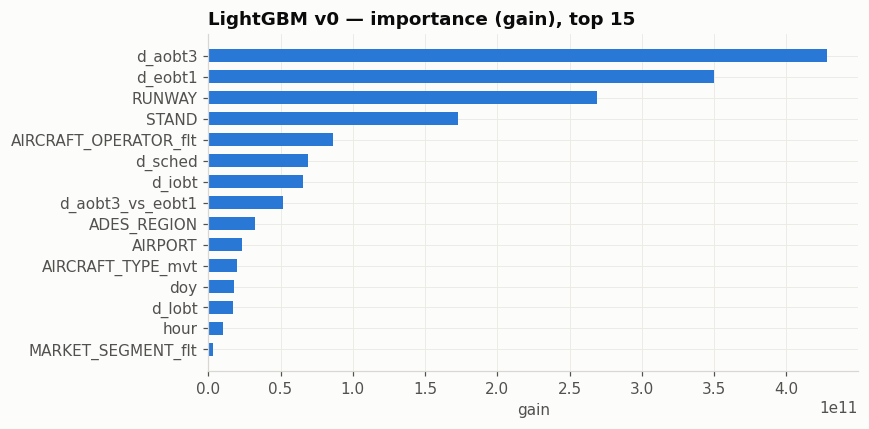

In [9]:
# §5c — importance des features
imp = pd.Series(model.feature_importance('gain'), index=model.feature_name()).sort_values().tail(15)
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(imp.index, imp.values, color=BLUE, height=0.62)
ax.set_title('LightGBM v0 — importance (gain), top 15', loc='left', fontweight='bold')
ax.set_xlabel('gain')
plt.tight_layout(); plt.show()

## §6 — 🔑 Expérience M2 : features d'état de l'aéroport / queue
Le levier n°1 identifié : le test étant **transductif** (tous les décollages, atterrissages,
AOBT_3 et taxi-in des arrivées de jan/juil 2026 sont visibles), on peut reconstruire
l'état de la surface au moment de chaque décollage — sur le train comme sur le ranking,
avec exactement le même code (`src/dc26/state_features.py`) :

- **`q_dep_aobt_to_takeoff_*`** : nb de décollages (aéroport / même piste) entre notre
  off-block (AOBT_3) et notre décollage → la file réellement subie ;
- **`q_backlog_at_takeoff`** : avions repoussés mais pas encore décollés à l'instant T ;
- débits passés/futurs (départs, arrivées, push-backs) sur 10/30/60 min ;
- gaps inter-décollages (piste et aéroport), y compris le **gap suivant** (transductif) ;
- congestion vue par les arrivées : taxi-in moyen de la dernière heure, avions en
  roulage d'arrivée à l'instant T.

Aucune de ces features n'utilise `BLOCK_TIME` ou `TAXITIME` des départs (masqués au test).

In [10]:
# §6 — construction des features d'etat (train + val, cache parquet)
from dc26.state_features import get_state_features
import time
t0 = time.time()
sf = get_state_features('train2025', dep, mv)
print(f"state features: {sf.shape} en {time.time()-t0:.0f}s")
X_all2 = pd.concat([X_all, sf], axis=1)
X_tr2, X_va2 = X_all2[clean], X_all2[dep.index.isin(val.index)]

state features: (2085047, 19) en 0s


best_iter=447 | M2: {'overall': 402.8, 'jan': 455.2, 'jul': 235.2}
gain vs M1: +3.1 s (+0.8%)


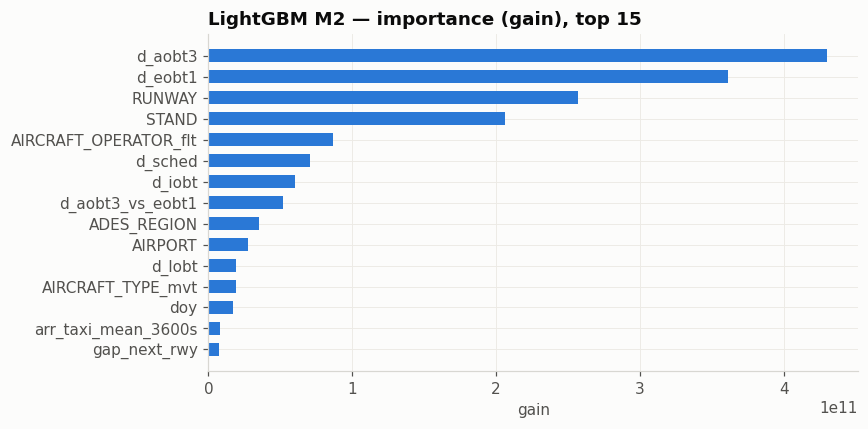

In [11]:
# §6b — LightGBM M2 = v0 + etat aeroport
dtrain2 = lgb.Dataset(X_tr2[~es_mask], y_tr[~es_mask], categorical_feature=cat_cols)
des2 = lgb.Dataset(X_tr2[es_mask], y_tr[es_mask], reference=dtrain2)
model2 = lgb.train(params, dtrain2, num_boost_round=4000, valid_sets=[des2],
                   callbacks=[lgb.early_stopping(150, verbose=False)])
pred2 = model2.predict(X_va2, num_iteration=model2.best_iteration)
rep2 = rmse_report(y_va.to_numpy(), pred2, val_part)
print(f"best_iter={model2.best_iteration} | M2: {({k: round(v,1) for k,v in rep2.items()})}")
print(f"gain vs M1: {rep['overall']-rep2['overall']:+.1f} s ({(rep['overall']-rep2['overall'])/rep['overall']:+.1%})")
log_experiment('M2 LightGBM + etat/queue', model='LightGBM',
               features='v0 + 18 state/queue features (transductive)',
               val_rmse=rep2['overall'], val_rmse_jan=rep2['jan'], val_rmse_jul=rep2['jul'],
               notes=f"best_iter={model2.best_iteration}", keep='KEEP')

imp2 = pd.Series(model2.feature_importance('gain'), index=model2.feature_name()).sort_values().tail(15)
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(imp2.index, imp2.values, color=BLUE, height=0.62)
ax.set_title('LightGBM M2 — importance (gain), top 15', loc='left', fontweight='bold')
ax.set_xlabel('gain')
plt.tight_layout(); plt.show()

## §7 — 🔑 Découverte n°2 : le RMSE est une affaire d'outliers
Analyse d'erreur de M2 sur le holdout (`scripts/analyze_m2.py`) — résultat décisif :

| Sous-ensemble | Part de l'erreur² totale |
|---|---:|
| top 0,1 % des lignes (218 vols) | **73,5 %** |
| les 43 vols avec taxi réel > 2 h | **69,8 %** |
| LIRF janvier | 41,6 % |
| LFPG janvier | 32,8 % |

Profil des extrêmes (580 vols > 2 h dans le train, dont 480 à LIRF) : **91 % non appariés
au Network Manager** (`FLIGHT_ID` manquant → pas d'AOBT_3, pas d'EOBT), tous IFR,
médiane 2,8 h, q90 9,8 h — vraisemblablement des artefacts de block time ou des retours
au parking. Signaux disponibles : aéroport, `has_fpl=0`, `MVT − SCHED` (médiane ~2 h 45).

→ Deux réponses testées : **M3** (garder les extrêmes dans le train) et **M4'**
(mixture de régimes calibrée).

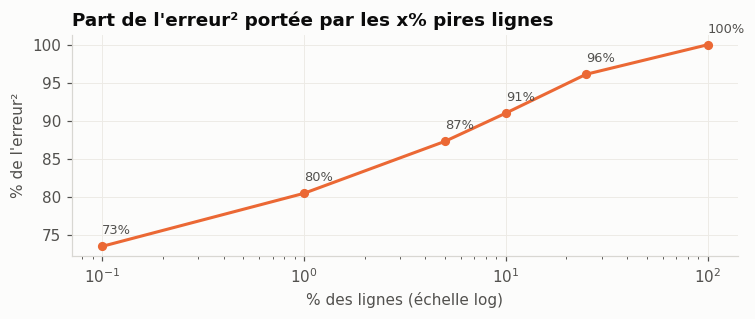

In [12]:
# §7 — budget d'erreur (depuis les predictions M2 sauvegardees)
pm2 = pd.read_parquet(ROOT / 'experiments' / 'preds_M2_holdout.parquet')
r = pm2.sort_values('sq', ascending=False).reset_index(drop=True)
total = r['sq'].sum()
fr = np.array([0.001, 0.01, 0.05, 0.10, 0.25, 1.0])
shares = [r['sq'][:int(len(r)*f)].sum()/total for f in fr]
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(fr*100, np.array(shares)*100, color=PAL[1], lw=2, marker='o', ms=5)
ax.set_xscale('log')
ax.set_title("Part de l'erreur² portée par les x% pires lignes", loc='left', fontweight='bold')
ax.set_xlabel('% des lignes (échelle log)'); ax.set_ylabel("% de l'erreur²")
for x, y in zip(fr*100, shares):
    ax.annotate(f'{y:.0%}', (x, y*100), textcoords='offset points', xytext=(0, 8), fontsize=8.5, color='#52514e')
plt.tight_layout(); plt.show()

## §8 — M3 & M4' : traiter le régime extrême
- **M3b** (`scripts/exp_m3.py`) : mêmes features + `has_fpl`, mais le train **garde les
  cibles extrêmes** (cap à 24 h). RMSE miroir : **360,7** (janvier 455 → 401). Le cap à
  4 h (M3c) est moins bon : l'amplitude compte.
- **M4'** (`scripts/exp_m4b.py`) : mixture de régimes — classifieur P(taxi > 2 h) calibré,
  puis `pred = (1−p)·E[y|normal] + p·E[y|extrême]`. RMSE miroir : **355,5**.
  La première version (M4, `scale_pos_weight` non calibré) était catastrophique (1440) —
  leçon : **toujours vérifier `mean(p) ≈ taux de base`**.

## §8bis — Exploration avancée : météo, ensembles, et la saga de la calibration
**Ce qui marche :**
- **METAR réel** (archives Iowa Mesonet, 2025 + jan/juil 2026 — le test étant dans le
  passé, la météo réelle est une donnée ouverte historique) : M5 = **346,4** (−9,1 s).
- **CatBoost en blend** sur le régresseur normal (w≈0,45, optimisé sur la fenêtre de
  calibration) : environ −2 s. Pipeline étagé anti-OOM : `scripts/m6_staged.py`.
- Meilleur score observé : **M6c = 337,3** (mixture + Platt scaling sur fenêtre décembre).

**Ce qui ne marche pas :**
- Target-encoding stand×piste naïf (M5b : 405,6 — fuite interne, il faudrait de l'out-of-fold) ;
- Config piste inférée (M8b : +1 s sur le régresseur seul — redondant avec AOBT_3/queue) ;
- Capacité LGBM accrue (M7b) ;
- **Et surtout : la calibration du classifieur d'extrêmes est une source de variance
  majeure** (±40 s sur janvier selon la « chance » de l'early-stopping) : isotonic → plateaux
  pathologiques (faux positifs juillet) ; OOF multi-folds → scores incomparables entre
  folds ; rounds fixes → overfitting des scores. Même moyennée sur 3 seeds, la mixture
  oscille entre 337 et 416 (M8a/M9).

**Batterie de robustesse (M9)** : le système **stable** est `m3bw` = un seul LightGBM,
extrêmes gardés (cap 24 h), features complètes avec météo, **aucune calibration** :
**359,7** reproductible (jan 399, jul 241). Les variantes à dégâts bornés et les
moyennes ne font pas mieux.

## §9 — Stratégie de soumission : deux tickets
Le classement retient **le meilleur RMSE parmi toutes les soumissions** → on soumet les
deux profils (construits par `scripts/make_submissions.py`, ré-entraînés sur tout 2025) :

| Version | Système | Miroir | Profil |
|---|---|---:|---|
| v3 | `m3bw` — LGBM unique, extrêmes gardés, météo | 359,7 | **stable** |
| v4 | mixture 3-seed Platt | 337–416 | variance haute, upside max |

(v1/v2 : itérations antérieures, remplacées.) La cellule ci-dessous vérifie les fichiers.

In [13]:
# §9 — verification des fichiers de soumission (construits par make_submissions.py)
rk_dep_ids = rk.loc[rk['PHASE_mvt'] == 'DEP', 'MVT_ID_mvt']
for v in [3, 4]:
    path = ROOT / 'submissions' / f'reliable-hamburger_v{v}.parquet'
    if not path.exists():
        print(f"v{v}: ABSENT — lancer scripts/make_submissions.py")
        continue
    s = pd.read_parquet(path)
    ok = (len(s) == 215876 and s['TAXITIME_SEC_mvt'].notna().all()
          and s['MVT_ID_mvt'].isin(rk_dep_ids).all())
    print(f"v{v}: {'OK' if ok else 'INVALIDE'} | n={len(s):,} mean={s['TAXITIME_SEC_mvt'].mean():.0f}s "
          f"median={s['TAXITIME_SEC_mvt'].median():.0f}s q99={s['TAXITIME_SEC_mvt'].quantile(.99):.0f}s "
          f">2h: {(s['TAXITIME_SEC_mvt']>7200).sum()}")

v3: OK | n=215,876 mean=1057s median=978s q99=2667s >2h: 39
v4: OK | n=215,876 mean=1062s median=979s q99=2762s >2h: 35


## §10 — Journal des expériences
Tableau append-only (`experiments/experiments.csv`) — chaque idée y passe :
hypothèse → implémentation → RMSE miroir → décision KEEP/DROP.

In [14]:
# §10 — etat du journal
log = load_log().sort_values('val_rmse')
display(log[['name', 'model', 'val_rmse', 'val_rmse_jan', 'val_rmse_jul', 'notes', 'keep']])

,name,model,val_rmse,val_rmse_jan,val_rmse_jul,notes,keep
7,M6c Platt mixture (blend),mixture Platt-cal,337.28,358.57,280.21,p_max=0.787,NaN
3,M5 mixture + METAR,mixture,346.39,381.75,242.35,NaN,NaN
2,M4' calibrated regime mixture,LGBM clf(iso) + 2 LGBM reg,355.48,390.47,253.49,p mean 0.00035 vs true 0.00020,KEEP
10,M7a mixture + runway config,mixture,357.65,397.65,236.73,NaN,NaN
14,"M9 robustness battery (A m3bw (stable, no cal))",see tag,359.67,399.26,240.58,"candidates: m3bw, mixture, capped, averages",KEEP
0,M3 extremes-in-train (M3b),LightGBM,360.73,400.66,240.41,error-budget driven: 43 rows >2h were 70% of s...,KEEP
11,M7b mixture big-capacity,mixture,363.01,402.88,243.18,NaN,NaN
5,M6 mixture + CatBoost blend,mixture(LGBM+CB),365.52,387.67,306.48,staged run,NaN
13,M8b stable-cal + runway config,mixture 3-seed cal,376.76,421.57,238.39,pA-only=403.4,NaN
8,M6d mixture airport-interaction clf,mixture Platt-cal v2,385.13,430.21,246.77,p_max=0.262,NaN


## §11 — Prochaines étapes (backlog priorisé)
1. ~~Queue/congestion~~ (M2) · ~~analyse d'erreur~~ · ~~régime extrême~~ (M3/M4) ·
   ~~METAR~~ (M5, −9 s) · ~~config piste~~ (M8b, drop) · ~~robustesse~~ (M9).
2. **Soumettre v3 + v4** et calibrer miroir ↔ leaderboard (l'écart nous dira si le
   miroir est fiable).
3. **Stabiliser la mixture** : le vrai problème est la variance de P(extrême) —
   pistes : positifs élargis (seuil 1 h → plus de données), features dédiées au
   classifieur (AIRPORT×no-fpl), moyenne sur 10+ seeds, prior bayésien par aéroport.
4. Bande 30 min–2 h (RMSE ~620, 7 % du budget) : régresseur quantile ou features dédiées.
5. CatBoost avec extrêmes pour blend sur m3bw ; XGBoost en 3e voix.
6. Prototype ADS-B OpenSky surface (observer le push-back réel des vols test).
7. Tuning Optuna une fois le set de features figé.
8. OOF target-encoding stand×piste (proprement, cette fois).

*Journal mis à jour automatiquement par `scripts/build_journal.py`.*